# Executing dynamic circuits in python to OpenQASM3

#### 1. Write a circuit using Qiskit API and try to export it in OpenQasm

In [ ]:
from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.circuit import MidCircuitMeasure
from qiskit.qasm3 import dumps, dump

# Write a circuit using Qiskit API and try to export its midcircuitmeasurement in OpenQasm

# service = QiskitRuntimeService()
# backend = service.least_busy(
#     operational=True, simulator=False, dynamic_circuits=True
# )

circ = QuantumCircuit(2, 2)
circ.x(0)
circ.append(MidCircuitMeasure(), [0], [0])
# circ.measure([0], [0])
# circ.measure_all()
print(circ.draw(cregbundle=False))


### OJO: MidCircuitMeasure() method NO ESTÁ SOPORTADO en la transpilación de qiskit -> OpenQAMS 3. Sin embargo, el measure() estandar si lo está. 
# Para los siguientes ejemplos el mid-circuit measurement lo implementaremos con measure()

     ┌───┐┌────────────┐
q_0: ┤ X ├┤0           ├
     └───┘│            │
q_1: ─────┤  Measure_2 ├
          │            │
c_0: ═════╡0           ╞
          └────────────┘
c_1: ═══════════════════
                        


#### 2. Dumping OpenQASM 3 file
Da error por usar MidCircuitMeasurement().<br>
**OJO:** MidCircuitMeasure() method NO ESTÁ SOPORTADO en la transpilación de qiskit -> OpenQAMS 3. <br>
Sin embargo, el measure() estandar si lo está. *Para los siguientes ejemplos el mid-circuit measurement lo implementaremos con measure()*

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("../data/0_")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

f = open(OUTPUT_DIR / "mcm_openqasm_3.txt", "w")
dump(circ, f)
f.close()

# Da error por usar MidCircuitMeasurement()

#### 3. Adding conditional gate with measure()

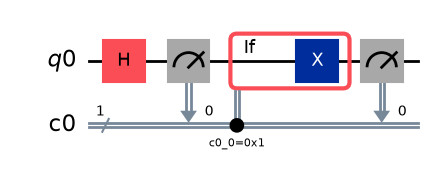

In [ ]:
# Create a dynamic circuit in Qiskit

qubits = QuantumRegister(1)
clbits = ClassicalRegister(1)
qc = QuantumCircuit(qubits, clbits)
(q0,) = qubits
(c0,) = clbits

qc.h(q0)
qc.measure(q0, c0)
with qc.if_test((c0, 1)):
    qc.x(q0)
qc.measure(q0, c0)

qc.draw(output='mpl')

#### 4. Dump OpenQASM 3 file
In this case we have no issues because we only relied on measure().

In [ ]:
f = open(OUTPUT_DIR / "mcm_conditioning_openqasm_3.txt", "w")
dump(qc, f)
f.close()


#### 5. Generating quantum teleportation script

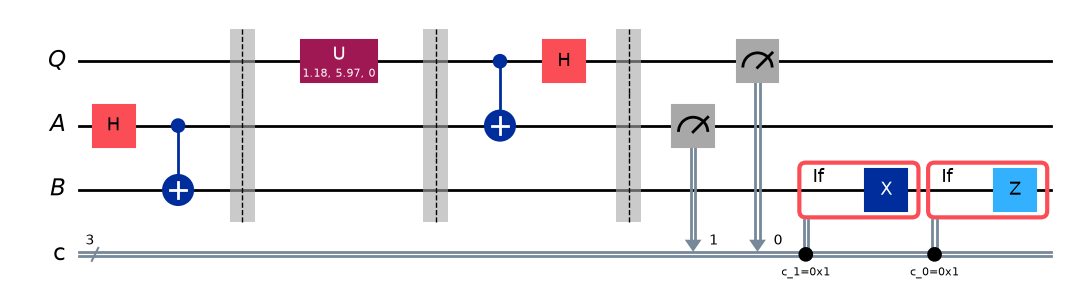

In [6]:
# Step 1: Map your problem to a quantum circuit

# Import some general packages
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
import numpy as np

# Define registers
secret = QuantumRegister(1, "Q")
Alice = QuantumRegister(1, "A")
Bob = QuantumRegister(1, "B")

cr = ClassicalRegister(3, "c")

qc = QuantumCircuit(secret, Alice, Bob, cr)

# We entangle Alice's and Bob's qubits as in our work above.
# We apply a Hadamard gate and then a CNOT gate.
# Note that the second argument in the CNOT gate is the target.
qc.h(Alice)
qc.cx(Alice, Bob)

# Inserting a barrier changes nothing about the logic. It just allows us to
# force gates to be positioned in "layers".
qc.barrier()

# Now we will use random variables to create the secret state.
# Don't worry about the "u" gate and the details.
np.random.seed(42)  # fixing seed for repeatability
theta = np.random.uniform(0.0, 1.0) * np.pi  # from 0 to pi
varphi = np.random.uniform(0.0, 2.0) * np.pi  # from 0 to 2*pi

# Assign the secret state to the qubit on the other side of Alice's (qubit 0), labeled Q
qc.u(theta, varphi, 0.0, secret)
qc.barrier()

# Now entangle Q and Alice's qubits as in the discussion above.
qc.cx(secret, Alice)
qc.h(secret)
qc.barrier()

# Now Alice measures her qubits, and stores the outcomes in the "classical registers" cr[]
qc.measure(Alice, cr[1])
qc.measure(secret, cr[0])

# Now we insert some conditional logic. If Alice measures Q in a "1" we need a Z gate, and if Alice
# measures A in a "1" we need an X gate (see the table).
with qc.if_test((cr[1], 1)):
    qc.x(Bob)
with qc.if_test((cr[0], 1)):
    qc.z(Bob)

qc.draw(output="mpl")

#### 6. Dump in OpenQASM 3

In [ ]:
f = open(OUTPUT_DIR / "teleportation_openqasm_3.txt", "w")
dump(qc, f)
f.close()


#### 7. Generate 3 bit repetition code

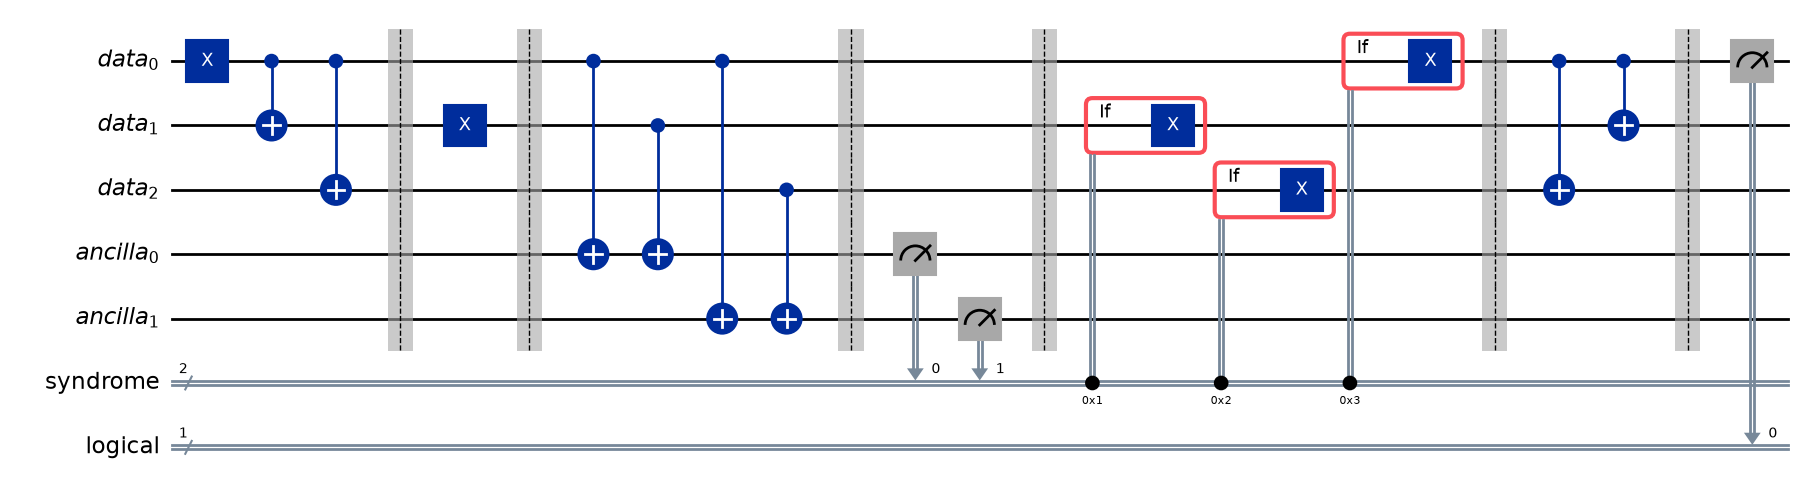

In [8]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt


data = QuantumRegister(3, "data")
ancilla = QuantumRegister(2, "ancilla")

syndrome = ClassicalRegister(2, "syndrome")
logical = ClassicalRegister(1, "logical")

qc = QuantumCircuit(data, ancilla, syndrome, logical)


# Prepare logical 1
qc.x(data[0])
qc.cx(data[0], data[1])
qc.cx(data[0], data[2])

qc.barrier()


# Introduce bit-flip error

qc.x(data[1])
qc.barrier()


# Syndrome extraction
qc.cx(data[0], ancilla[0])
qc.cx(data[1], ancilla[0])

# Ancilla s1 stores q0 XOR q2
qc.cx(data[0], ancilla[1])
qc.cx(data[2], ancilla[1])

qc.barrier()


# Mid circuit mesurement
qc.measure(ancilla[0], syndrome[0])
qc.measure(ancilla[1], syndrome[1])

qc.barrier()


# ============================================================
# 6. CLASSICALLY CONTROLLED CORRECTION
# ============================================================


# Syndrome = 01 -> q1 was flipped
with qc.if_test((syndrome, 1)):
    qc.x(data[1])

# Syndrome = 10 -> q2 was flipped
with qc.if_test((syndrome, 2)):
    qc.x(data[2])

# Syndrome = 11 -> q0 was flipped
with qc.if_test((syndrome, 3)):
    qc.x(data[0])

qc.barrier()

# 7. Decode

qc.cx(data[0], data[2])
qc.cx(data[0], data[1])
qc.barrier()

# 8. Final measurement
qc.measure(data[0], logical[0])

# 9. Print circuit
qc.draw(output='mpl')


#### 8. Dump in OpenQASM 3

In [ ]:
f = open(OUTPUT_DIR / "3_BRC_correction_openqasm_3.txt", "w")
dump(qc, f)
f.close()
